In [1]:
import pandas as pd

path = "../data/brfss_survey_data_2024.csv"
all_cols = pd.read_csv(path, nrows=0).columns.tolist()
print(len(all_cols))
print(all_cols[:40])

301
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX3', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX3', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'LASTDEN4', 'RMVTETH4']


In [2]:
wanted = ["DIABETE4", "_RFHYPE6", "_CHOLCH3", "_BMI5", "SMOKE100",
          "CVDSTRK3", "_MICHD", "_TOTINDA", "_AGEG5YR", "SEXVAR",
          "GENHLTH", "PHYSHLTH", "MENTHLTH", "DIFFWALK", "EDUCA", "INCOME3"]

found = [c for c in wanted if c in all_cols]
missing = [c for c in wanted if c not in all_cols]
print("Found:", found)
print("Not found:", missing)

print()
print("Diabetes-related columns:", [c for c in all_cols if "DIAB" in c])
print("BMI-related columns:", [c for c in all_cols if "BMI" in c])
print("Blood pressure / cholesterol columns:", [c for c in all_cols if "HYP" in c or "CHOL" in c or "BPHIGH" in c])

Found: ['DIABETE4', '_BMI5', 'SMOKE100', 'CVDSTRK3', '_MICHD', '_TOTINDA', '_AGEG5YR', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'DIFFWALK', 'EDUCA', 'INCOME3']
Not found: ['_RFHYPE6', '_CHOLCH3']

Diabetes-related columns: ['DIABETE4', 'DIABAGE4', 'PDIABTS1', 'PREDIAB2', 'DIABTYPE', 'DIABEYE1', 'DIABEDU1']
BMI-related columns: ['_BMI5', '_BMI5CAT', '_RFBMI5']
Blood pressure / cholesterol columns: []


In [3]:
features = found + ["EXERANY2"]
df_raw = pd.read_csv(path, usecols=features)
print("Loaded:", df_raw.shape)

df = df_raw[df_raw["DIABETE4"].isin([1, 3])].copy()
df["Outcome"] = (df["DIABETE4"] == 1).astype(int)

print("Rows kept:", df.shape)
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))

Loaded: (457670, 15)
Rows kept: (441934, 16)
Outcome
0    376125
1     65809
Name: count, dtype: int64
Outcome
0    0.851
1    0.149
Name: proportion, dtype: float64


In [4]:
import numpy as np

# Remove the original diabetes answer: Outcome was built from it,
# so keeping it would let the model "cheat".
df = df.drop(columns="DIABETE4")

# BMI is stored multiplied by 100
df["_BMI5"] = df["_BMI5"] / 100

# Yes/No questions: 1 = yes, 2 = no, 7/9 = don't know / refused
for c in ["SMOKE100", "CVDSTRK3", "DIFFWALK", "EXERANY2"]:
    df[c] = df[c].replace({1: 1, 2: 0, 7: np.nan, 9: np.nan})

df["_MICHD"] = df["_MICHD"].replace({1: 1, 2: 0})                 # heart disease
df["_TOTINDA"] = df["_TOTINDA"].replace({1: 1, 2: 0, 9: np.nan})  # physically active
df["SEXVAR"] = df["SEXVAR"].replace({1: 0, 2: 1})                 # 0 = male, 1 = female
df["_AGEG5YR"] = df["_AGEG5YR"].replace({14: np.nan})             # 14 = missing
df["GENHLTH"] = df["GENHLTH"].replace({7: np.nan, 9: np.nan})
df["EDUCA"] = df["EDUCA"].replace({9: np.nan})
df["INCOME3"] = df["INCOME3"].replace({77: np.nan, 99: np.nan})

# Days of poor health: 88 = none (0 days), 77/99 = missing
for c in ["PHYSHLTH", "MENTHLTH"]:
    df[c] = df[c].replace({88: 0, 77: np.nan, 99: np.nan})

print("Missing values (%):")
print((df.isna().mean() * 100).round(1))
print()
print(df.describe().T[["min", "max"]])

df.to_csv("../data/brfss2024_clean.csv", index=False)

Missing values (%):
SEXVAR       0.0
GENHLTH      0.3
PHYSHLTH     2.4
MENTHLTH     1.7
EXERANY2     0.3
CVDSTRK3     0.3
EDUCA        0.5
INCOME3     19.0
DIFFWALK     4.5
SMOKE100     6.9
_TOTINDA     0.3
_MICHD       1.1
_AGEG5YR     1.8
_BMI5        9.4
Outcome      0.0
dtype: float64

           min    max
SEXVAR     0.0   1.00
GENHLTH    1.0   5.00
PHYSHLTH   0.0  30.00
MENTHLTH   0.0  30.00
EXERANY2   0.0   1.00
CVDSTRK3   0.0   1.00
EDUCA      1.0   6.00
INCOME3    1.0  11.00
DIFFWALK   0.0   1.00
SMOKE100   0.0   1.00
_TOTINDA   0.0   1.00
_MICHD     0.0   1.00
_AGEG5YR   1.0  13.00
_BMI5     12.0  99.84
Outcome    0.0   1.00


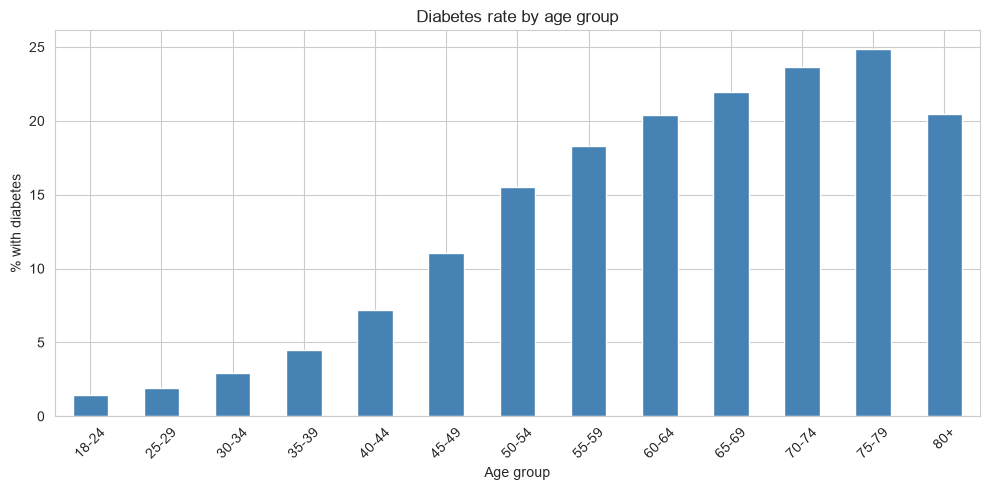

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

age_labels = {1:"18-24", 2:"25-29", 3:"30-34", 4:"35-39", 5:"40-44", 6:"45-49",
              7:"50-54", 8:"55-59", 9:"60-64", 10:"65-69", 11:"70-74", 12:"75-79", 13:"80+"}

rate = df.groupby("_AGEG5YR")["Outcome"].mean() * 100
rate.index = [age_labels[int(i)] for i in rate.index]

plt.figure(figsize=(10, 5))
rate.plot(kind="bar", color="steelblue")
plt.title("Diabetes rate by age group")
plt.ylabel("% with diabetes")
plt.xlabel("Age group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/diabetes_by_age.png", dpi=150)
plt.show()

C:\Users\nrkod\AppData\Local\Temp\ipykernel_18132\3124616598.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels(["No diabetes", "Diabetes"])


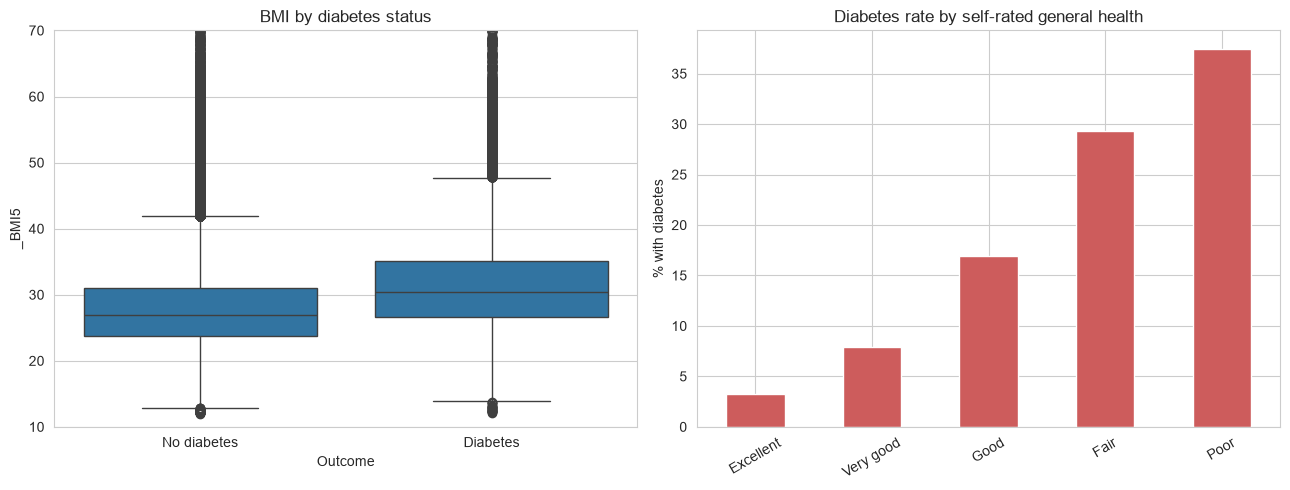

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Outcome", y="_BMI5", ax=ax[0])
ax[0].set_title("BMI by diabetes status")
ax[0].set_xticklabels(["No diabetes", "Diabetes"])
ax[0].set_ylim(10, 70)

health = df.groupby("GENHLTH")["Outcome"].mean() * 100
health.index = ["Excellent", "Very good", "Good", "Fair", "Poor"]
health.plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Diabetes rate by self-rated general health")
ax[1].set_ylabel("% with diabetes")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../reports/bmi_and_health.png", dpi=150)
plt.show()

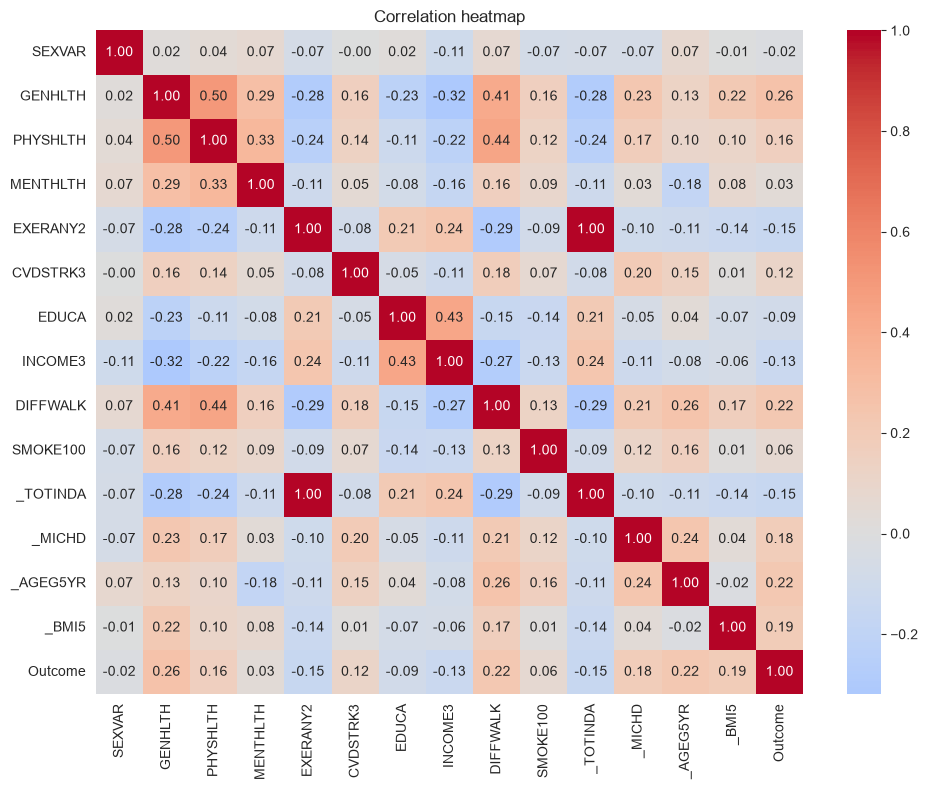

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("../reports/correlation_heatmap.png", dpi=150)
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Drop the duplicate column
df_model = df.drop(columns=["_TOTINDA"])
X = df_model.drop(columns="Outcome")
y = df_model["Outcome"]

# Split FIRST: 80% to train, 20% to test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Pipeline: fill blanks -> scale -> logistic regression
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
logreg.fit(X_train, y_train)

pred = logreg.predict(X_test)
prob = logreg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, target_names=["No diabetes", "Diabetes"]))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

Train: (353547, 13)  Test: (88387, 13)
              precision    recall  f1-score   support

 No diabetes       0.94      0.71      0.81     75225
    Diabetes       0.30      0.73      0.43     13162

    accuracy                           0.71     88387
   macro avg       0.62      0.72      0.62     88387
weighted avg       0.84      0.71      0.75     88387

ROC-AUC: 0.793
Confusion matrix:
[[53292 21933]
 [ 3553  9609]]


In [10]:
import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import recall_score, precision_score, f1_score

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=50,
                                         class_weight="balanced", n_jobs=-1, random_state=42))]),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             scale_pos_weight=neg/pos, n_jobs=-1, random_state=42,
                             eval_metric="logloss"),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}

results = [{
    "Model": "Logistic Regression",
    "Recall": recall_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, prob),
}]
trained = {"Logistic Regression": logreg}

for name, m in models.items():
    start = time.time()
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    trained[name] = m
    results.append({
        "Model": name,
        "Recall": recall_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "F1": f1_score(y_test, p),
        "ROC-AUC": roc_auc_score(y_test, pr),
    })
    print(f"{name} done in {time.time()-start:.0f} seconds")

comparison = pd.DataFrame(results).round(3).sort_values("ROC-AUC", ascending=False)
print()
print(comparison.to_string(index=False))

Random Forest done in 55 seconds
XGBoost done in 17 seconds
HistGradientBoosting done in 10 seconds

               Model  Recall  Precision    F1  ROC-AUC
HistGradientBoosting   0.787      0.297 0.432    0.804
             XGBoost   0.779      0.297 0.431    0.803
       Random Forest   0.781      0.296 0.429    0.802
 Logistic Regression   0.730      0.305 0.430    0.793


Saved model, feature names and comparison table


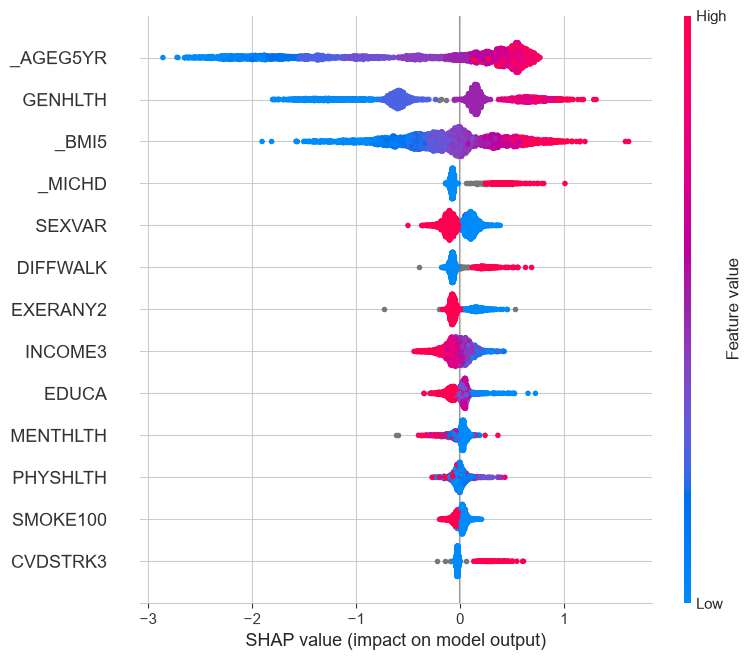

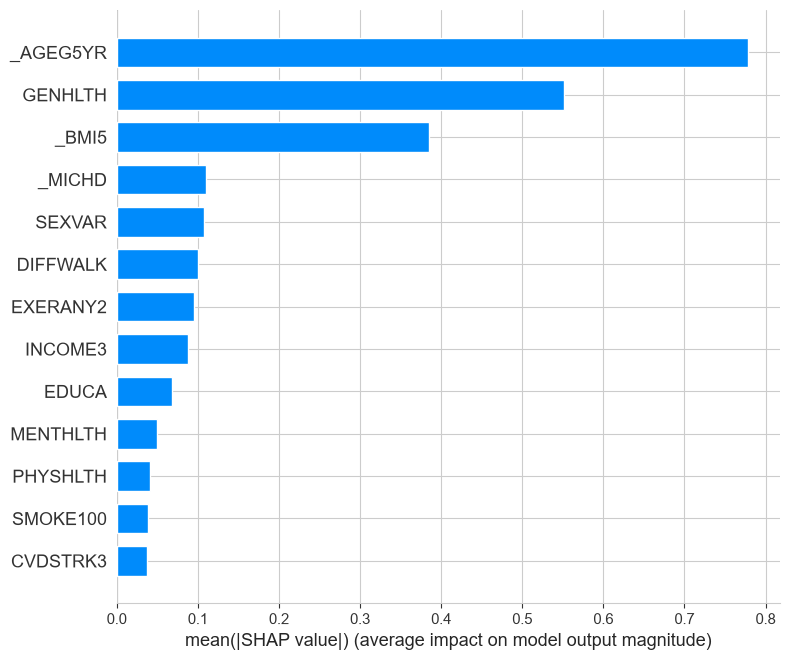

In [11]:
import joblib
import shap
import matplotlib.pyplot as plt

# 1. Save the final model and the comparison table
xgb_model = trained["XGBoost"]
joblib.dump(xgb_model, "../models/xgb_model.pkl")
joblib.dump(list(X.columns), "../models/feature_names.pkl")
comparison.to_csv("../reports/model_comparison.csv", index=False)
print("Saved model, feature names and comparison table")

# 2. SHAP: which features push risk up or down?
sample = X_test.sample(3000, random_state=42)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(sample)

plt.figure()
shap.summary_plot(shap_values, sample, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../reports/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
from sklearn.metrics import recall_score, precision_score

prob_xgb = trained["XGBoost"].predict_proba(X_test)[:, 1]

print("Average predicted risk:", round(prob_xgb.mean(), 3))
print("Real diabetes rate:    ", round(y_test.mean(), 3))
print()

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (prob_xgb >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Recall": recall_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "% of people flagged": p.mean() * 100,
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

Average predicted risk: 0.395
Real diabetes rate:     0.149

 Threshold  Recall  Precision  % of people flagged
       0.3   0.921      0.238               57.702
       0.4   0.865      0.264               48.697
       0.5   0.779      0.297               39.019
       0.6   0.653      0.342               28.428
       0.7   0.468      0.403               17.288
       0.8   0.232      0.496                6.952
